In [ ]:
%pwd

'/content'

In [ ]:
# lets mount the drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
cd /content/drive/MyDrive/Walnut1/

/content/drive/MyDrive/Walnut1


In [ ]:
ls

Projections/  Reconstructions/


In [ ]:
pip install astra-toolbox

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.4/14.4 MB 7.7 MB/s  0:00:01


load data


ERROR:tifffile:<TiffTag.fromfile> raised TiffFileError('<tifffile.TiffTag 320 @1493217> invalid value offset 0')
ERROR:tifffile:<TiffTag.fromfile> raised TiffFileError('<tifffile.TiffTag 320 @1493217> invalid value offset 0')
ERROR:tifffile:<TiffTag.fromfile> raised TiffFileError('<tifffile.TiffTag 320 @1493217> invalid value offset 0')


6.235 sec elapsed
pre-process data & calibrate intensities
5.843 sec elapsed
Running Empirical Scatter Correction (ESC) on GPU (Tesla T4)...
Starting Nelder-Mead optimization for ESC coefficients on GPU...
Optimal coefficients found: [0.06048776 0.0579286  0.05977334 0.05086394]
Applying scatter correction to full resolution projections...


/tmp/ipykernel_411/2264174631.py:232: RuntimeWarning: Maximum number of iterations has been exceeded.
  res = minimize(objective_function, initial_guess, method='Nelder-Mead', options=opt_options)


397.343 sec elapsed for ESC
Final pre-processing log transformation
2.315 sec elapsed
compute final reconstruction on Tesla T4 GPU...
2.325 sec elapsed
save results
128.977 sec elapsed


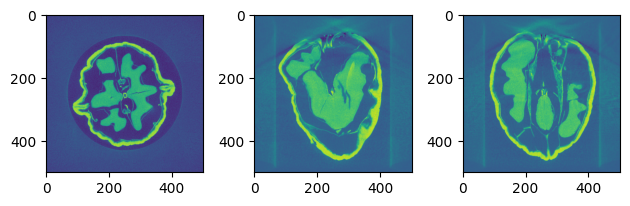

In [ ]:
import numpy as np
import astra
import os
import imageio.v2 as imageio
import time
import gc
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter, zoom
from scipy.optimize import minimize
from skimage.filters import threshold_otsu

def generate_pep_basis(proj_intensity, m, n, eps, sigma_u, sigma_v):
    W = np.where(proj_intensity < eps, proj_intensity, 0.0)
    safe_proj = np.clip(proj_intensity, 1e-5, 2.0)
    minus_ln_I = -np.log(safe_proj)

    W_clipped = np.maximum(W, 1e-6)
    ln_clipped = np.maximum(minus_ln_I, 1e-6)

    base_term = (W_clipped ** m) * (ln_clipped ** n)
    basis = gaussian_filter(base_term, sigma=(sigma_v, sigma_u))
    return basis

def get_segmentation_masks_and_ref(vol):
    """
    Generates air mask and walnut interior mask using Otsu thresholding.
    """
    thresh = threshold_otsu(vol)
    air_mask = vol < (thresh * 0.5)         # Strictly background air
    walnut_mask = vol >= (thresh * 0.5)     # The actual walnut (shell + kernel)
    return air_mask, walnut_mask

def objective_function(params):
    c_i = params[:n_basis]
    c_1 = params[n_basis]

    # Strictly penalize negative or exploding coefficients
    if np.any(c_i < 0) or c_1 < 0.1 or c_1 > 10.0:
        return 1e9

    scatter_est = np.zeros_like(proj_sub_down)
    for idx, b in enumerate(bases):
        scatter_est += c_i[idx] * b

    ratio = proj_sub_down / np.maximum(scatter_est, 1e-6)
    min_ratio_per_angle = ratio.reshape(n_sub, -1).min(axis=1)
    k_alpha = np.minimum(1.0, np.minimum(min_ratio_per_angle * (1.0 - delta), 1.0))
    k_alpha = k_alpha[:, None, None]

    proj_cor = proj_sub_down - k_alpha * scatter_est
    proj_cor = np.clip(proj_cor, 1e-5, 2.0)

    sino_cor = -np.log(proj_cor)
    sino_cor = np.ascontiguousarray(np.transpose(sino_cor, (1, 0, 2)))

    vol_rec_opt = np.zeros(vol_sz_opt, dtype=np.float32)
    v_id = astra.data3d.link('-vol', vol_geom_opt, vol_rec_opt)
    p_id = astra.data3d.link('-sino', proj_geom_opt, sino_cor)

    cfg = astra.astra_dict('FDK_CUDA')
    cfg['ProjectionDataId'] = p_id
    cfg['ReconstructionDataId'] = v_id
    a_id = astra.algorithm.create(cfg)
    astra.algorithm.run(a_id, 1)
    astra.algorithm.delete(a_id)
    astra.data3d.delete(p_id)
    astra.data3d.delete(v_id)

    vol_scaled = c_1 * vol_rec_opt
    air_vals = vol_scaled[air_mask]
    walnut_vals = vol_scaled[walnut_mask]

    cost = 0.0

    # Penalty 1: Air background should be close to 0 attenuation
    if air_vals.size > 0:
        cost += np.sum(np.abs(air_vals)) / air_vals.size

    # Penalty 2: Penalize negative values inside the walnut (physical impossibility/overcorrection)
    if walnut_vals.size > 0:
        neg_penalties = np.maximum(0.0, -walnut_vals)
        cost += 5.0 * (np.sum(neg_penalties) / walnut_vals.size)

        # Penalty 3: Cupping reduction via internal spatial smoothness/variance penalty
        cost += 0.5 * np.std(walnut_vals)

    return cost


#### user defined settings #####################################################

walnut_id = 1
orbit_id = 1
angluar_sub_sampling = 2  # Sub-sampling set to 2 for safe RAM management
voxel_per_mm = 10

data_path = '/content/drive/MyDrive'
recon_path = '/content/drive/MyDrive/Walnut1/WalnutsOwnReconstructions'


#### load data #################################################################

t = time.time()
print('load data', flush=True)

data_path_full = os.path.join(data_path, 'Walnut{}'.format(walnut_id), 'Projections', 'tubeV{}'.format(orbit_id))
projs_name = 'scan_{:06}.tif'
dark_name = 'di000000.tif'
flat_name = ['io000000.tif', 'io000001.tif']
vecs_name = 'scan_geom_corrected.geom'
projs_rows = 972
projs_cols = 768

vecs = np.loadtxt(os.path.join(data_path_full, vecs_name))
vecs = vecs[range(0, 1200, angluar_sub_sampling)]
projs_idx = range(1200, 0, -angluar_sub_sampling)

n_pro = vecs.shape[0]
projs = np.zeros((n_pro, projs_rows, projs_cols), dtype=np.float32)

trafo = lambda image : np.transpose(np.flipud(image))

dark = trafo(imageio.imread(os.path.join(data_path_full, dark_name)))
flat = np.zeros((2, projs_rows, projs_cols), dtype=np.float32)

for i, fn in enumerate(flat_name):
    flat[i] = trafo(imageio.imread(os.path.join(data_path_full, fn)))
flat = np.mean(flat, axis=0)

for i in range(n_pro):
    projs[i] = trafo(imageio.imread(os.path.join(data_path_full, projs_name.format(projs_idx[i]))))

print(round(time.time() - t, 3), 'sec elapsed')


### pre-process data (Intensity domain) #################-----------------------

t = time.time()
print('pre-process data & calibrate intensities', flush=True)

projs = projs.astype(np.float32) - dark
projs /= (flat - dark)
projs = np.clip(projs, 1e-5, 2.0)
projs_intensity = projs.copy()

# Free raw projections array and dark/flat frames from RAM immediately
del projs, dark, flat
gc.collect()

print(round(time.time() - t, 3), 'sec elapsed')


### EMPIRICAL SCATTER CORRECTION (ESC) STEP #################-------------------

t = time.time()
print('Running Empirical Scatter Correction (ESC) on GPU (Tesla T4)...', flush=True)

angle_stride = max(1, int(2 / (360 / n_pro)))
downsample_factor = 4

proj_sub = projs_intensity[::angle_stride]
n_sub, h_sub, w_sub = proj_sub.shape
h_down, w_down = h_sub // downsample_factor, w_sub // downsample_factor

proj_sub_down = np.zeros((n_sub, h_down, w_down), dtype=np.float32)
for i in range(n_sub):
    proj_sub_down[i] = zoom(proj_sub[i], 1.0 / downsample_factor, order=1)

pep_params = [
    {'m': 1.0, 'n': 1.0, 'eps': 0.95, 'sigma_u': 120 // downsample_factor, 'sigma_v': 120 // downsample_factor},
    {'m': 2.0, 'n': 1.0, 'eps': 0.90, 'sigma_u': 80 // downsample_factor, 'sigma_v': 80 // downsample_factor},
    {'m': 1.0, 'n': 2.0, 'eps': 0.98, 'sigma_u': 60 // downsample_factor, 'sigma_v': 60 // downsample_factor},
]

bases = []
for p in pep_params:
    b_stack = np.zeros_like(proj_sub_down)
    for i in range(n_sub):
        b_stack[i] = generate_pep_basis(proj_sub_down[i], **p)
    bases.append(b_stack)

bases.append(np.ones_like(proj_sub_down))
n_basis = len(bases)

opt_voxel_per_mm = voxel_per_mm / 2.0
vol_sz_opt = 3 * (int(50 * opt_voxel_per_mm) + 1,)
vol_geom_opt = astra.create_vol_geom(vol_sz_opt)
vox_sz_opt = 1 / opt_voxel_per_mm
for k_opt in ['WindowMinX', 'WindowMaxX', 'WindowMinY', 'WindowMaxY', 'WindowMinZ', 'WindowMaxZ']:
    vol_geom_opt['option'][k_opt] *= vox_sz_opt

vecs_sub = vecs[::angle_stride].copy()
vecs_sub[:, [3, 4, 5, 6, 7, 8]] /= downsample_factor
proj_geom_opt = astra.create_proj_geom('cone_vec', h_down, w_down, vecs_sub)

# Initial reconstruction using GPU FDK_CUDA
init_sino = -np.log(np.clip(proj_sub_down, 1e-5, 2.0))
init_sino = np.transpose(init_sino, (1, 0, 2))
init_vol = np.zeros(vol_sz_opt, dtype=np.float32)

vol_id_opt = astra.data3d.link('-vol', vol_geom_opt, init_vol)
proj_id_opt = astra.data3d.link('-sino', proj_geom_opt, np.ascontiguousarray(init_sino))
cfg_opt = astra.astra_dict('FDK_CUDA')
cfg_opt['ProjectionDataId'] = proj_id_opt
cfg_opt['ReconstructionDataId'] = vol_id_opt
alg_id_opt = astra.algorithm.create(cfg_opt)
astra.algorithm.run(alg_id_opt, 1)
astra.algorithm.delete(alg_id_opt)
astra.data3d.delete(proj_id_opt)
astra.data3d.delete(vol_id_opt)

air_mask, walnut_mask = get_segmentation_masks_and_ref(init_vol)
del init_vol
gc.collect()

delta = 1.0 / 11.0

###### run the cost function
initial_guess = [0.05] * n_basis + [1.0]

print("Starting Nelder-Mead optimization for ESC coefficients on GPU...", flush=True)

# Increased maxiter and added tighter convergence tolerances to prevent early cutoff
opt_options = {
    'maxiter': 100,       # Allow more iterations for proper convergence
    'xatol': 1e-4,       # Parameter tolerance
    'fatol': 1e-4,       # Cost function tolerance
    'disp': True
}

res = minimize(objective_function, initial_guess, method='Nelder-Mead', options=opt_options)
optimal_c = res.x
opt_c_i = optimal_c[:n_basis]
opt_c_1 = optimal_c[n_basis]

print("Optimal coefficients found:", opt_c_i)

print("Applying scatter correction to full resolution projections...", flush=True)
full_scatter_est = np.zeros_like(projs_intensity)
for idx, p_param in enumerate(pep_params):
    b_full = np.zeros_like(projs_intensity)
    for i in range(n_pro):
        b_full[i] = generate_pep_basis(projs_intensity[i], **p_param)
    full_scatter_est += opt_c_i[idx] * b_full
full_scatter_est += opt_c_i[-1]

full_ratio = projs_intensity / np.maximum(full_scatter_est, 1e-6)
full_min_ratio = full_ratio.reshape(n_pro, -1).min(axis=1)
full_k_alpha = np.minimum(1.0, np.minimum(full_min_ratio * (1.0 - delta), 1.0))[:, None, None]

projs_intensity -= full_k_alpha * full_scatter_est
projs_intensity = np.clip(projs_intensity, 1e-5, 2.0)

del bases, full_scatter_est, full_ratio
gc.collect()

print(round(time.time() - t, 3), 'sec elapsed for ESC')


### Final Pre-processing (Negative Log) #################-----------------------
t = time.time()
print('Final pre-processing log transformation', flush=True)

projs = -np.log(projs_intensity)
del projs_intensity
gc.collect()

projs = np.transpose(projs, (1, 0, 2))
projs = np.ascontiguousarray(projs)

print(round(time.time() - t, 3), 'sec elapsed')

### compute FDK reconstruction #################--------------------------------

t = time.time()
print('compute final reconstruction on Tesla T4 GPU...', flush=True)

vol_sz = 3 * (50 * voxel_per_mm + 1,)
vox_sz = 1 / voxel_per_mm
vol_rec = np.zeros(vol_sz, dtype=np.float32)

vol_geom = astra.create_vol_geom(vol_sz)
for k_opt in ['WindowMinX', 'WindowMaxX', 'WindowMinY', 'WindowMaxY', 'WindowMinZ', 'WindowMaxZ']:
    vol_geom['option'][k_opt] *= vox_sz

proj_geom = astra.create_proj_geom('cone_vec', projs_rows, projs_cols, vecs)

vol_id = astra.data3d.link('-vol', vol_geom, vol_rec)
proj_id = astra.data3d.link('-sino', proj_geom, projs)

cfg_fdk = astra.astra_dict('FDK_CUDA')
cfg_fdk['ProjectionDataId'] = proj_id
cfg_fdk['ReconstructionDataId'] = vol_id
alg_id = astra.algorithm.create(cfg_fdk)

astra.algorithm.run(alg_id, 1)

astra.algorithm.delete(alg_id)
astra.data3d.delete(proj_id)
astra.data3d.delete(vol_id)

print(round(time.time() - t, 3), 'sec elapsed')


### save reconstruction #################---------------------------------------

t = time.time()
print('save results', flush=True)

f, ax = plt.subplots(1, 3, sharex=False, sharey=False)
ax[0].imshow(vol_rec[vol_sz[0]//2,:,:])
ax[1].imshow(vol_rec[:,vol_sz[1]//2,:])
ax[2].imshow(vol_rec[:,:,vol_sz[2]//2])
f.tight_layout()

recon_path_full = os.path.join(recon_path, 'Walnut{}'.format(walnut_id))

if not os.path.exists(recon_path_full):
    os.makedirs(recon_path_full)

for i in range(vol_sz[0]):
    slice_path = os.path.join(recon_path_full, 'fdk_pos{}_ass{}_vmm{}_{:06}.tiff'.format(orbit_id,
                                  angluar_sub_sampling, voxel_per_mm, i))
    imageio.imwrite(slice_path, vol_rec[i,...])

print(round(time.time() - t, 3), 'sec elapsed')

# **Results and data analysis**

In [ ]:
# compare the reconstructed FDK data using ESC vs AGD50 ground truth data and comment
# on the validation of the method